# CBE 130 Lab 1: Python Basics and Forward Euler Method

In this lab, we will start with basic Python operations review, intro to NumPy and Matplotlib, and then use the forward Euler method to approximate the concentration in a simple reactor model.

By the end of the lab, you should be able to write small Python programs, work with arrays, make clear plots, and step through a first-order ordinary differential equation.

## Learning Objectives

- Implement simple Python assignment, printing, `if` statements, and `for` loops.
- Create and inspect NumPy arrays used for engineering calculations.
- Compare loop-based calculations with NumPy vectorized calculations.
- Create clear Matplotlib line plots with titles, axis labels, grids, and legends.
- Apply the forward Euler method to a first-order chemical engineering model.

## Setup

In [ ]:
# The time library will let us measure how long a calculation takes.
import time

# NumPy is used for arrays and numerical calculations.
import numpy as np

# Matplotlib is used for plotting results.
import matplotlib.pyplot as plt

## Part 1: Basic Python Operations

Python stores information in variables. A variable can hold one number, one word, or a list of values. We will use these tools later to store reactor concentrations, time values, and numerical approximations.

In [ ]:
# Store simple values in variables.
a = 1
b = 2

# Store several values in a list.
c = [1, 2, 3]

# print(...) displays a value on the screen.
print(f"{a}")
print(f"{b}")
print(f"{c}")

# Python can use variables in calculations.
total = a + b
print(f"a + b = {total}")

In [ ]:
# This variable stores the reactor temperature in degrees Celsius.
reactor_temperature_c = 85.0

# An if statement lets Python choose between two paths.
if reactor_temperature_c > 80.0:
    print("The reactor is above the target temperature.")
else:
    print("The reactor is at or below the target temperature.")

In [ ]:
# A for loop repeats the same action for each value in a list.
concentration_values = [1.00, 0.82, 0.67]

for concentration in concentration_values:
    print(f"Concentration of A = {concentration} mol/L")

Concentration of A = 1.0 mol/L
Concentration of A = 0.82 mol/L
Concentration of A = 0.67 mol/L
Concentration of A at index 0 = 1.0 mol/L
Concentration of A at index 1 = 0.82 mol/L
Concentration of A at index 2 = 0.67 mol/L


## Part 2: NumPy Basics

NumPy is a Python library for numerical computing. It is especially useful when we have many measurements or many time points, such as concentration readings from a reactor experiment.

### Arrays: Creation and Inspection

In [ ]:
concentration_list = [1.00, 0.82, 0.67, 0.55]

# np.array(...) converts the list into a NumPy array.
concentration_array = np.array(concentration_list)

print(f"concentration_array: {concentration_array}")

# .shape tells us how many entries are in the array. Used a LOOOTTT!
print(f"shape: {concentration_array.shape}")

# .dtype tells us what type of data the array stores.
print(f"data type: {concentration_array.dtype}")

concentration_array: [1.   0.82 0.67 0.55]
shape: (4,)
data type: float64


In [16]:
# np.zeros(5) creates an array with 5 zeros.
zeros_array = np.zeros(5)

# np.ones((3, 3)) creates a 3 by 3 array filled with ones.
ones_array = np.ones((3, 3))

# np.linspace(start, end, number_of_points) creates evenly spaced values.
# This line creates 6 values starting at 0.0 and ending at 10.0.
time_values = np.linspace(0.0, 10.0, 6)

# np.arange(start, end, step) creates values separated by a fixed step.
# The end value is not included, so this gives 0, 2, 4, 6, and 8.
sample_numbers = np.arange(0, 10, 2)

print(f"zeros_array: {zeros_array}")
print(f"ones_array: {ones_array}")
print(f"time_values: {time_values}")
print(f"sample_numbers: {sample_numbers}")

zeros_array: [0. 0. 0. 0. 0.]
ones_array: [[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]
time_values: [ 0.  2.  4.  6.  8. 10.]
sample_numbers: [0 2 4 6 8]


### Indexing

Indexing lets us access one value from an array. Python starts counting at index 0.

In [18]:
# This array stores temperature measurements in degrees Celsius.
temperature_values = np.array([25.0, 40.0, 55.0, 70.0])

# Python uses zero-based indexing, so index 0 means the first value.
first_temperature = temperature_values[0]
second_temperature = temperature_values[1]
last_temperature = temperature_values[3]

print(f"first temperature: {first_temperature} deg C")
print(f"second temperature: {second_temperature} deg C")
print(f"last temperature: {last_temperature} deg C")

for index, concentration in enumerate(concentration_values):
    print(f"Concentration of A at index {index} = {concentration} mol/L")

first temperature: 25.0 deg C
second temperature: 40.0 deg C
last temperature: 70.0 deg C
Concentration of A at index 0 = 1.0 mol/L
Concentration of A at index 1 = 0.82 mol/L
Concentration of A at index 2 = 0.67 mol/L


### Array Math and Vectorized Calculations

A vectorized calculation applies an operation to an entire NumPy array at once. This is much faster and cleaner than updating values one at a time in a loop.

In [21]:
# Concentration measurements for reactant A in mol/L.
concentration_a = np.array([1.00, 0.82, 0.67, 0.55])

# This formula computes conversion from each concentration value.
# NumPy applies the calculation to every value in the array.
conversion = (1.00 - concentration_a) / 1.00

print(f"concentration_a: {concentration_a}")
print(f"conversion: {conversion}")

concentration_a: [1.   0.82 0.67 0.55]
conversion: [0.   0.18 0.33 0.45]


In [23]:
# Temperatures measured in degrees Celsius.
temperature_c = np.array([25.0, 40.0, 55.0, 70.0])

# Add 273.15 to every value to convert from deg C to K.
temperature_k = temperature_c + 273.15

print(f"temperature in deg C: {temperature_c}")
print(f"temperature in K: {temperature_k}")

temperature in deg C: [25. 40. 55. 70.]
temperature in K: [298.15 313.15 328.15 343.15]


In [24]:
rate_constant = 0.15

# Create 6 evenly spaced time values from 0.0 min to 20.0 min.
time_values = np.linspace(0.0, 20.0, 6)

# np.exp(...) computes e raised to a power for every value in the array.
concentration_values = np.exp(-rate_constant * time_values)

print(f"time values: {time_values}")
print(f"concentration values: {concentration_values}")

time values: [ 0.  4.  8. 12. 16. 20.]
concentration values: [1.         0.54881164 0.30119421 0.16529889 0.09071795 0.04978707]


### Motivation Experiment: Loops vs NumPy

Suppose we have a very large number of concentration measurements and want to compute conversion for each one. We can do this with a loop, but NumPy can do the same calculation much faster.

In [ ]:
number_of_points = 50000000
initial_concentration = 1.0

# Create 1,000,000 concentration values from 1.0 mol/L down to 0.1 mol/L.
large_concentration_array = np.linspace(1.0, 0.1, number_of_points)

# Convert the NumPy array to a Python list for the loop calculation.
large_concentration_list = large_concentration_array.tolist()
conversion_list = []

# time.time() records the current clock time in seconds.
loop_start_time = time.time()
for concentration in large_concentration_list:
    conversion_value = (initial_concentration - concentration) / initial_concentration
    conversion_list.append(conversion_value)
loop_end_time = time.time()
loop_time = loop_end_time - loop_start_time

print(f"Loop calculation time: {loop_time} seconds")

Loop calculation time: 4.2067201137542725 seconds


In [30]:
# Now do the same calculation with one NumPy vectorized operation.
numpy_start_time = time.time()
conversion_array = (initial_concentration - large_concentration_array) / initial_concentration
numpy_end_time = time.time()
numpy_time = numpy_end_time - numpy_start_time

print(f"NumPy calculation time: {numpy_time} seconds")

NumPy calculation time: 0.2560751438140869 seconds


### Question 2.1: Quick NumPy Exercises

1. Create a 1D array with values 5, 4, 3, 2, 1 using one NumPy call.
2. Make a 4 by 4 array filled with 7s.
3. Using array math, take a 3 by 3 array of zeros and add the vector `[1, 2, 3]` to each row.
4. Create `x` with 50 points from -1 to 1 and compute `y = 3x^2 - 2x + 1` using vectorized operations.

In [ ]:
# 1. Create a 1D array with values 5, 4, 3, 2, 1.
array_1 = np.array([5, 4, 3, 2, 1])

# 2. Make a 4 by 4 array filled with 7s.
array_2 = np.ones((4, 4)) * 7

# 3. Add the vector [1, 2, 3] to each row of a 3 by 3 zero array.
zero_array = np.zeros((3, 3))
row_vector = np.array([1, 2, 3])
array_3 = zero_array + row_vector

# 4. Create x values and compute y = 3x^2 - 2x + 1.
# np.linspace(-1.0, 1.0, 50) creates 50 evenly spaced x values.
x = np.linspace(-1.0, 1.0, 50)
y = 3 * x**2 - 2 * x + 1

print("Exercise 1 array:")
print(f"{array_1}")
print("Exercise 2 array:")
print(f"{array_2}")
print("Exercise 3 array:")
print(f"{array_3}")
print("Exercise 4 y values:")
print(f"{y}")

## Part 3: Matplotlib Basics

Matplotlib lets us visualize numerical results. In chemical engineering, plots often make it easier to interpret trends in temperature, concentration, conversion, pressure, or flow rate.

### Line Plot

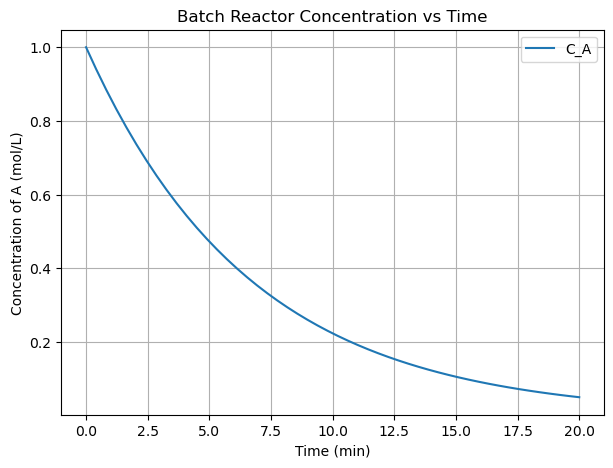

In [32]:
# Create 200 evenly spaced time values from 0.0 min to 20.0 min.
time_values = np.linspace(0.0, 20.0, 50)
rate_constant = 0.15

# Compute concentration for a first-order batch reactor model.
concentration_values = np.exp(-rate_constant * time_values)

# Create a new figure with width 7 inches and height 5 inches.
plt.figure(figsize=(7, 5))

# Plot concentration on the y-axis against time on the x-axis.
plt.plot(time_values, concentration_values, label="C_A")
plt.title("Batch Reactor Concentration vs Time")
plt.xlabel("Time (min)")
plt.ylabel("Concentration of A (mol/L)")
plt.legend()
plt.grid(True)
plt.show()

### Multiple Curves

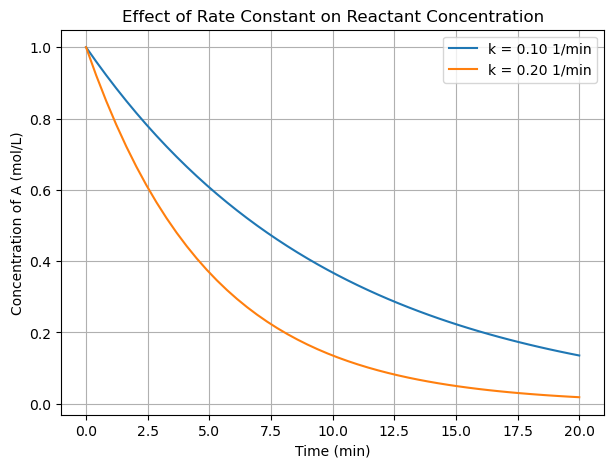

In [33]:
# Create 200 evenly spaced time values from 0.0 min to 20.0 min.
time_values = np.linspace(0.0, 20.0, 50)

rate_constant_1 = 0.10
rate_constant_2 = 0.20

# Compute two concentration curves using two different rate constants.
concentration_1 = np.exp(-rate_constant_1 * time_values)
concentration_2 = np.exp(-rate_constant_2 * time_values)

plt.figure(figsize=(7, 5))
plt.plot(time_values, concentration_1, label="k = 0.10 1/min")
plt.plot(time_values, concentration_2, label="k = 0.20 1/min")
plt.title("Effect of Rate Constant on Reactant Concentration")
plt.xlabel("Time (min)")
plt.ylabel("Concentration of A (mol/L)")
plt.legend()
plt.grid(True)
plt.show()

### Question 3.1: Quick Matplotlib Exercises

1. Create `time_values` from 0 to 10 min with 100 points.
2. Compute `temperature_values = 25 + 5 * time_values`.
3. Plot temperature vs time.
4. Include a title, axis labels with units, a legend, and a grid.

In [ ]:
# 1. Create time values from 0 to 10 min with 100 points.
time_values = np.linspace(0.0, 10.0, 100)

# 2. Compute temperature at each time value.
temperature_values = 25.0 + 5.0 * time_values

# 3 and 4. Plot temperature vs time with clear labels.
plt.figure(figsize=(7, 5))
plt.plot(time_values, temperature_values, label="Temperature")
plt.title("Reactor Temperature vs Time")
plt.xlabel("Time (min)")
plt.ylabel("Temperature (deg C)")
plt.legend()
plt.grid(True)
plt.show()

## Part 4: First-Order ODEs and Euler Method

Many chemical engineering models describe how a quantity changes with time. For example, the concentration of a reactant in a constant-volume batch reactor can be described by an ordinary differential equation.

### Guided Problem 1: Analytical Solution for a Batch Reactor


$$ \frac{dx}{dt} = \frac{5}{t}\,x$$
with the initial condition \(x(1)=1\), defined on t in[1,3].

**a. Classification**  
- **Order:** First order  
- **Linear?** Yes. Standard form: $(x'(t) - \tfrac{5}{t}x(t)=0$.  
- **Homogeneous?** Yes. There is no forcing term (right-hand side equals 0 in linear form).

**b. General solution**  
Separate variables:
$$
\frac{1}{x}\,dx = \frac{5}{t}\,dt
\quad\Rightarrow\quad
\ln|x| = 5\ln|t| + C
\quad\Rightarrow\quad
x(t) = C\,t^{5}.
$$

**c. Particular solution** x(1)=1:
$$
1 = C\cdot 1^{5} \Rightarrow C=1
\quad\Rightarrow\quad
\boxed{x(t)=t^{5}}.
$$

**d. Plot the particular solution**  


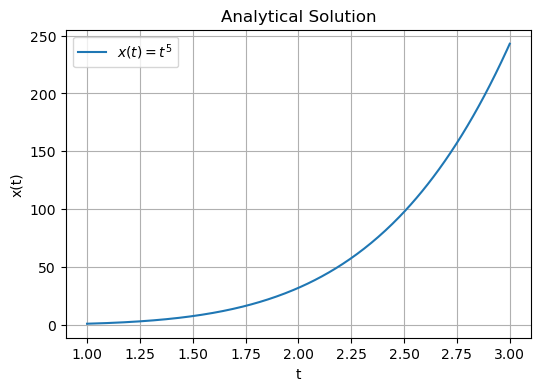

In [36]:
# Particular solution derived above:
def x_exact(t):
    return t**5

# Grid on [1, 3]
t = np.linspace(1.0, 3.0, 300)
x = x_exact(t)

# Plot
plt.figure(figsize=(6,4))
plt.plot(t, x, label=r'$x(t)=t^{5}$')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.title("Analytical Solution")
plt.grid(True)
plt.legend()
plt.show()

### Forward Euler's Method

The **forward Euler's method** takes insight from the forward difference approximation with a constant step size

$$
y'(x_i) = \dfrac{y(x_{i+1}) - y(x_{i})}{\Delta x},
$$

and rearrange it to make $y(x_{i+1})$ explicit, we have

$$
y(x_{i+1}) = y(x_{i}) + y'(x_i)\Delta x.
$$

More generally, because the derivative from the ODE depends on both $x$ and $y$ ($y' = f(x, y)$), we can write this as

$$
\boxed{y(x_{i+1}) = y(x_{i}) + y'(x_i, y(x_i))\Delta x}.
$$

Note that we know everything on the right hand side, which allows us to solve the left hand side explicitly. The forward Euler's method is therefore an **explicit method**. We can solve for the next steps iteratively.



In [38]:
def dxdt(t, x):
    return 5 * x / t

dt = 0.001
t_initial = 1
t_final = 3
t = np.arange(t_initial, t_final+dt/2, dt)
t_len = len(t)

x_forward = np.zeros(t_len)
x_forward[0] = 1

for i in range(t_len - 1):
    x_forward[i+1] = x_forward[i] + dxdt(t[i], x_forward[i]) * dt

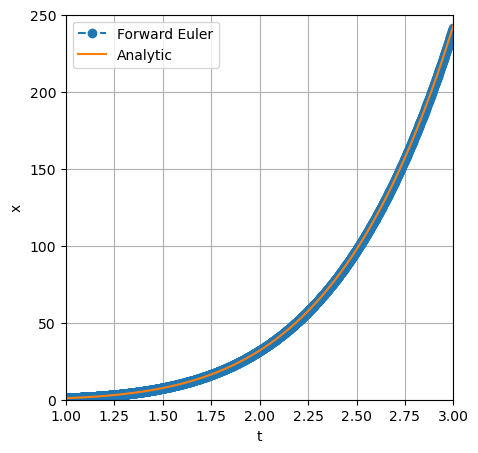

In [43]:
plt.subplots(figsize=(5, 5))
plt.plot(t, x_forward, 'o--', label='Forward Euler')
plt.plot(t, x_exact(t), '-', label='Analytic')
plt.xlim(1, 3)
plt.ylim(0, 250)
plt.xlabel('t')
plt.ylabel('x')
plt.grid(True)
plt.legend()

### Question 5.1: Practice Problem 1

A liquid-phase first-order reaction is carried out in a constant-volume batch reactor. The initial concentration of A is `2.0 mol/L`, and the rate constant is `0.30 1/min`.

Use forward Euler with a time step of `0.5 min` to estimate `C_A` from `t = 0 min` to `t = 10 min`.

Your tasks:

1. Store the time values and Euler concentration values in arrays.
2. Compute the analytical concentration at the same time values.
3. Print the final Euler concentration and final analytical concentration.
4. Plot both curves on the same figure.
5. In one sentence, explain whether the Euler approximation is close to the analytical solution.

In [ ]:
initial_concentration = 2.0
rate_constant = 0.30
time_start = 0.0
time_end = 10.0
time_step = 0.5

# Compute the number of Euler steps from the time interval and time step.
number_of_steps = int((time_end - time_start) / time_step)

# Create empty arrays for time and concentration values.
time_values = np.zeros(number_of_steps + 1)
euler_concentration = np.zeros(number_of_steps + 1)

# Store the initial condition.
time_values[0] = time_start
euler_concentration[0] = initial_concentration

# Apply the forward Euler method one step at a time.
for step_index in range(number_of_steps):
    current_time = time_values[step_index]
    current_concentration = euler_concentration[step_index]
    slope = -rate_constant * current_concentration
    next_concentration = current_concentration + time_step * slope

    time_values[step_index + 1] = current_time + time_step
    euler_concentration[step_index + 1] = next_concentration

# Compute the exact analytical concentration at the same time values.
analytical_concentration = initial_concentration * np.exp(-rate_constant * time_values)

print(f"Euler final concentration: {euler_concentration[-1]} mol/L")
print(f"Analytical final concentration: {analytical_concentration[-1]} mol/L")

plt.figure(figsize=(7, 5))
plt.plot(time_values, euler_concentration, label="Euler approximation")
plt.plot(time_values, analytical_concentration, label="Analytical solution")
plt.title("Practice Problem: Batch Reactor Euler Approximation")
plt.xlabel("Time (min)")
plt.ylabel("Concentration of A (mol/L)")
plt.legend()
plt.grid(True)
plt.show()

print("The Euler approximation is close to the analytical solution, but it has some error because the time step is finite.")